# FitCheck.AI — Machine Learning Analysis

**Author:** Swayam Shakya

This notebook builds the two models behind FitCheck.AI's outfit score:

| Model | Question it answers |
|---|---|
| **Decision Tree** | Given the occasion, weather, the person's stated preferences and an outfit's features, how likely are they to like it? |
| **K-Nearest Neighbours** | The same question, answered by looking at the most similar outfits that have already been rated. |

The trained models are saved as Joblib files in `ml/models/`. The FitCheck.AI server
(`backend/`) loads them at start-up and blends them with the rule-based scores
(occasion, weather, colour, style).

### About the data

A new app has no ratings yet, so this notebook **creates a synthetic dataset**: simulated people,
each with their own wardrobe and a hidden sense of taste, rating outfits in different situations.
It is not real user data and the metrics below describe how well the models recover the simulated
taste, not real-world accuracy. Two things keep it honest and useful:

* Outfit features are computed by `ml/fitcheck_ml/features.py`, the reference implementation that the
  browser's `assets/js/engine/features.js` mirrors exactly (a parity test checks this), so the models
  see exactly what they will see in the app.
* Each simulated person's taste includes traits the models **cannot observe** (running hot or cold,
  loving contrast) plus random noise, so the task can't be solved perfectly — just like real people.

Once real feedback accumulates in the `outfit_feedback` table, the same pipeline can be re-run on it.

## 1. Setup

In [1]:
import sys, json, math, random, platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib
import sklearn

from sklearn.model_selection import GroupShuffleSplit, GridSearchCV, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve,
                             ConfusionMatrixDisplay)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
ML_DIR = ROOT / "ml"
DATA_DIR = ROOT / "notebooks" / "data"
EXPORT_DIR = ML_DIR / "models"
DATA_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# The same feature and rule code the browser engine mirrors
sys.path.insert(0, str(ML_DIR))
from fitcheck_ml import catalog, rules, features, color, ml

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

print("Python", platform.python_version(), "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__)
print("Engine package:", ML_DIR / "fitcheck_ml")
print("Features per outfit:", len(features.feature_names()))

Python 3.13.18 | scikit-learn 1.9.1 | pandas 3.0.5 | numpy 2.5.3
Engine package: /home/claude/FitCheck.AI/ml/fitcheck_ml
Features per outfit: 53


## 2. Dataset creation

Three ingredients:

1. **Wardrobes** — every simulated person gets ~18 garments. Subcategory, colour, style,
   seasons and occasion tags are sampled so they hang together the way real wardrobes do
   (a blazer is more likely navy than neon and more likely tagged for work than for sport).
2. **Situations** — an occasion, a weather condition and a temperature that fits it
   (no 30 °C snow days).
3. **Taste** — a hidden utility for each person. It rewards outfits that fit the occasion and
   weather, but also depends on the person's palette and style preferences and on unobserved
   quirks. A rating is drawn from that utility with noise.

In [2]:
rng = np.random.default_rng(SEED)

COLOR_POOLS = {
    "top":       ["white", "light blue", "grey", "black", "navy", "cream", "charcoal", "pink",
                  "green", "burgundy", "mustard", "lavender", "red", "olive", "coral", "mint"],
    "bottom":    ["denim", "navy", "black", "khaki", "beige", "grey", "olive", "brown", "charcoal",
                  "cream", "burgundy", "light blue"],
    "dress":     ["black", "navy", "red", "burgundy", "pink", "lavender", "green", "cream", "mustard",
                  "light blue", "magenta"],
    "outerwear": ["navy", "black", "camel", "khaki", "olive", "grey", "denim", "brown", "charcoal",
                  "beige", "burgundy"],
    "footwear":  ["white", "black", "brown", "camel", "grey", "navy", "beige", "red", "blue"],
    "accessory": ["brown", "black", "camel", "grey", "navy", "white", "red", "mustard", "green"],
}
# the first colours in each pool are the common ones
def pick_color(category):
    pool = COLOR_POOLS[category]
    weights = np.linspace(2.5, 0.6, len(pool))
    name = rng.choice(pool, p=weights / weights.sum())
    return color.NAMED_COLORS[name], name

def pick_style(attrs):
    if "sporty" in attrs["tags"]:
        return rng.choice(["sporty", "streetwear"], p=[0.8, 0.2])
    f = attrs["formality"]
    if f >= 4:
        return rng.choice(["classic", "elegant", "smart_casual", "minimalist"], p=[0.4, 0.3, 0.2, 0.1])
    if f <= 1:
        return rng.choice(["streetwear", "minimalist", "sporty", "smart_casual"], p=[0.45, 0.3, 0.15, 0.1])
    return rng.choice(["minimalist", "classic", "smart_casual", "streetwear", "elegant"],
                      p=[0.25, 0.25, 0.25, 0.15, 0.10])

def pick_seasons(attrs):
    base = {0: ["spring", "summer"], 1: ["spring", "summer", "autumn"],
            2: ["autumn", "winter", "spring"], 3: ["winter", "autumn"]}[attrs["warmth"]]
    if rng.random() < 0.15:
        base = list(catalog.SEASONS)
    return base

def pick_occasions(attrs, style):
    tags = []
    for occ, rule in catalog.OCCASION_RULES.items():
        lo, hi = rule["formality"]
        f = attrs["formality"]
        close = lo - 1 <= f <= hi + 1
        if rule["sporty"] is True:
            close = "sporty" in attrs["tags"] or style == "sporty"
        if rule["sporty"] is False and ("sporty" in attrs["tags"]):
            close = False
        if close and rng.random() < (0.85 if lo <= f <= hi else 0.35):
            tags.append(occ)
    return tags or ["casual"]

_next_id = [0]
def make_item(category):
    sub = rng.choice(sorted(catalog.SUBCATEGORIES[category]))
    attrs = catalog.attributes(category, sub)
    hex_, name = pick_color(category)
    style = pick_style(attrs)
    _next_id[0] += 1
    return {"id": _next_id[0], "name": f"{name} {sub}", "category": category, "subcategory": sub,
            "main_color_hex": hex_, "main_color_name": name, "secondary_color_hex": None,
            "style": style, "seasons": pick_seasons(attrs), "occasions": pick_occasions(attrs, style)}

WARDROBE_SHAPE = {"top": 5, "bottom": 4, "dress": 1, "footwear": 3, "outerwear": 2, "accessory": 3}
def make_wardrobe():
    items = []
    for cat, n in WARDROBE_SHAPE.items():
        if cat == "dress" and rng.random() < 0.5:
            continue
        items += [make_item(cat) for _ in range(n)]
    return items

TEMP_BY_WEATHER = {"sunny": (8, 35), "cloudy": (-2, 25), "rainy": (3, 22), "snowy": (-15, 2), "windy": (-5, 20)}
def make_context(person):
    weather = rng.choice(catalog.WEATHER, p=[0.32, 0.28, 0.2, 0.08, 0.12])
    lo, hi = TEMP_BY_WEATHER[weather]
    return {
        "occasion": rng.choice(catalog.OCCASIONS),
        "weather": weather,
        "temperature_c": round(float(rng.uniform(lo, hi)), 1),
        "style": rng.choice(person["styles"]) if rng.random() < 0.4 else None,
        "palette": person["palette"] if rng.random() < 0.6 else "any",
        "preferred_styles": person["styles"],
        "favorite_colors": [], "avoided_colors": [],
    }

def make_person(pid):
    return {
        "person_id": pid,
        "palette": rng.choice(catalog.PALETTES[1:]),
        "styles": list(rng.choice(catalog.STYLES, size=2, replace=False)),
        # hidden quirks the models never see directly
        "runs_cold": rng.normal(0, 0.35),
        "contrast_love": rng.normal(0, 0.012),
        "strictness": rng.uniform(0.6, 1.4),
    }
print(make_item("top"))

{'id': 1, 'name': 'navy athletic top', 'category': 'top', 'subcategory': np.str_('athletic top'), 'main_color_hex': '#1f2a4a', 'main_color_name': np.str_('navy'), 'secondary_color_hex': None, 'style': np.str_('streetwear'), 'seasons': ['spring', 'summer'], 'occasions': ['casual', 'sports', 'travel']}


In [3]:
def sample_outfit(wardrobe, ctx, smart):
    by = {c: [it for it in wardrobe if it["category"] == c] for c in catalog.CATEGORIES}

    def choose(pool):
        if not pool:
            return None
        if not smart:
            return pool[rng.integers(len(pool))]
        w = np.exp(4 * np.array([rules.item_prefit(it, ctx) for it in pool]))
        return pool[rng.choice(len(pool), p=w / w.sum())]

    use_dress = by["dress"] and rng.random() < 0.25
    outfit = [choose(by["dress"])] if use_dress else [choose(by["top"]), choose(by["bottom"])]
    outfit.append(choose(by["footwear"]))
    p_outer = 0.9 if ctx["temperature_c"] < 12 else (0.5 if ctx["temperature_c"] < 20 else 0.15)
    if by["outerwear"] and rng.random() < p_outer:
        outfit.append(choose(by["outerwear"]))
    for _ in range(rng.integers(0, 3)):
        acc = choose(by["accessory"])
        if acc and acc not in outfit:
            outfit.append(acc)
    return [it for it in outfit if it]


def hidden_utility(f, person):
    """The simulated person's real taste. Not available to the models."""
    s = person["strictness"]
    u = (2.4 * s * (f["rule_occasion"] - 0.62)
         + 2.2 * (f["rule_weather"] - 0.62)
         + 2.0 * (f["rule_color"] - 0.66)
         + 1.3 * (f["rule_style"] - 0.62))
    # palette taste (this one *is* visible through the palette feature)
    pal = person["palette"]
    if pal == "bold":
        u += 0.7 if f["n_bold"] >= 1 else -0.5
    elif pal in ("neutral", "monochrome"):
        u += 0.35 * (f["n_neutral"] / max(1, f["n_items"] - f["n_accessories"])) - 0.35 * f["n_bold"]
    elif pal == "earthy":
        u += 0.3 * f["n_earthy"] - 0.25 * f["n_bold"]
    elif pal == "pastel":
        u += 0.35 * f["n_pastel"] - 0.15 * f["n_bold"]
    # hidden quirks
    u += person["runs_cold"] * f["warmth_gap"]
    u += person["contrast_love"] * (f["lightness_range"] - 35)
    u -= 0.25 * max(0, f["formality_spread"] - 2)
    return u


rows = []
N_PEOPLE, CONTEXTS, OUTFITS_PER_CONTEXT = 320, 8, 4
for pid in range(N_PEOPLE):
    person = make_person(pid)
    wardrobe = make_wardrobe()
    for _ in range(CONTEXTS):
        ctx = make_context(person)
        for k in range(OUTFITS_PER_CONTEXT):
            outfit = sample_outfit(wardrobe, ctx, smart=(k % 2 == 0))
            if not any(it["category"] == "footwear" for it in outfit):
                continue
            rr = rules.score_rules(outfit, ctx)
            f = features.build_features(outfit, ctx, rr)
            u = hidden_utility(f, person) + rng.normal(0, 0.55)
            liked = int(rng.random() < 1 / (1 + math.exp(-2.2 * u)))
            weakest = rr["color"]["detail"]["weakest_pair"]
            rows.append({**f, "person_id": pid, "person_palette": person["palette"],
                         "harmony_kind": weakest["kind"] if weakest else "single",
                         "items": "|".join(it["name"] for it in outfit), "liked": liked})

raw = pd.DataFrame(rows)
raw.to_csv(DATA_DIR / "outfit_ratings.csv", index=False)
print(f"Generated {len(raw):,} rated outfits from {N_PEOPLE} people -> {DATA_DIR / 'outfit_ratings.csv'}")

Generated 10,240 rated outfits from 320 people -> /home/claude/FitCheck.AI/notebooks/data/outfit_ratings.csv


## 3. Dataset loading

In [4]:
df = pd.read_csv(DATA_DIR / "outfit_ratings.csv")
print(df.shape)
df.head()

(10240, 36)


,temperature_c,total_warmth,warmth_gap,mean_formality,formality_spread,n_items,has_outerwear,n_accessories,is_dress,n_neutral,...,rule_color,occasion,weather,style_pref,palette,person_id,person_palette,harmony_kind,items,liked
0,20.4,2,-1,3.000000,3,4,0,1,0,3,...,0.6680,party,cloudy,none,bold,0,bold,neutral-flat,white polo|khaki jeans|black dress shoes|navy cap,1
1,20.4,0,-3,2.333333,4,5,0,2,0,2,...,0.7466,party,cloudy,none,bold,0,bold,clash,red athletic top|navy shorts|black dress shoes...,0
2,20.4,3,0,3.333333,3,4,0,1,0,2,...,0.5254,party,cloudy,none,bold,0,bold,clash,burgundy turtleneck|khaki jeans|black dress sh...,1
3,20.4,1,-2,2.666667,4,3,0,0,0,2,...,0.9309,party,cloudy,none,bold,0,bold,anchored,red athletic top|khaki jeans|black dress shoes,1
4,24.2,1,-1,2.333333,4,4,0,1,0,2,...,0.7394,casual,sunny,none,bold,0,bold,clash,red athletic top|brown cargo pants|black dress...,1


## 4. Dataset description

In [5]:
print("Columns:", len(df.columns))
print("Numeric features:", len(features.NUMERIC_FEATURES), "| categorical:", list(features.CATEGORICAL_FEATURES))
print()
print("Like rate: {:.1%}".format(df["liked"].mean()))
print("Rows per person: {:.1f}".format(df.groupby("person_id").size().mean()))
df[features.NUMERIC_FEATURES[:12]].describe().T.round(2)

Columns: 36
Numeric features: 27 | categorical: ['occasion', 'weather', 'style_pref', 'palette']

Like rate: 69.6%
Rows per person: 32.0


,count,mean,std,min,25%,50%,75%,max
temperature_c,10240.0,13.00,10.31,-14.9,6.30,13.45,19.9,35.0
total_warmth,10240.0,2.99,1.61,0.0,2.00,3.00,4.0,10.0
warmth_gap,10240.0,-0.88,1.65,-6.0,-2.00,-1.00,0.0,6.0
mean_formality,10240.0,2.30,0.83,1.0,1.67,2.33,3.0,5.0
formality_spread,10240.0,2.01,1.20,0.0,1.00,2.00,3.0,4.0
n_items,10240.0,4.34,0.93,2.0,4.00,4.00,5.0,6.0
has_outerwear,10240.0,0.59,0.49,0.0,0.00,1.00,1.0,1.0
n_accessories,10240.0,0.88,0.73,0.0,0.00,1.00,1.0,2.0
is_dress,10240.0,0.13,0.34,0.0,0.00,0.00,0.0,1.0
n_neutral,10240.0,2.56,0.94,0.0,2.00,3.00,3.0,4.0


In [6]:
df[["occasion", "weather", "style_pref", "palette", "harmony_kind"]].describe().T

,count,unique,top,freq
occasion,10240,8,travel,1388
weather,10240,5,sunny,3244
style_pref,10240,7,none,6092
palette,10240,6,any,3960
harmony_kind,10240,7,neutral-flat,6445


## 5. Data cleaning

The generated data is complete, but the same checks are run that real exported feedback would need:
missing values, impossible values, unknown categories and exact duplicates.

In [7]:
before = len(df)
report = {}

report["missing values"] = int(df[features.NUMERIC_FEATURES + list(features.CATEGORICAL_FEATURES)].isna().sum().sum())
df = df.dropna(subset=features.NUMERIC_FEATURES + list(features.CATEGORICAL_FEATURES) + ["liked"])

valid_range = df["temperature_c"].between(-40, 50) & df["n_items"].between(2, 8)
for col in ["rule_occasion", "rule_weather", "rule_style", "rule_color", "occasion_tag_frac", "sporty_frac"]:
    valid_range &= df[col].between(0, 1)
report["out-of-range rows"] = int((~valid_range).sum())
df = df[valid_range]

valid_cat = np.ones(len(df), dtype=bool)
for field, cats in features.CATEGORICAL_FEATURES.items():
    valid_cat &= df[field].isin(cats).to_numpy()
report["unknown categories"] = int((~valid_cat).sum())
df = df[valid_cat]

dupes = df.duplicated(subset=features.NUMERIC_FEATURES + list(features.CATEGORICAL_FEATURES) + ["person_id"])
report["duplicates"] = int(dupes.sum())
df = df[~dupes].reset_index(drop=True)

df["liked"] = df["liked"].astype(int)
for k, v in report.items():
    print(f"{k:>20}: {v}")
print(f"{'kept':>20}: {len(df):,} of {before:,}")

      missing values: 0
   out-of-range rows: 0
  unknown categories: 0
          duplicates: 48
                kept: 10,192 of 10,240


## 6. Exploratory data analysis

In [8]:
summary = pd.DataFrame({
    "like rate by occasion": df.groupby("occasion")["liked"].mean(),
}).sort_values("like rate by occasion")
print(summary.round(3))
print()
print(df.groupby("weather")["liked"].agg(["mean", "count"]).round(3))

          like rate by occasion
occasion                       
sports                    0.529
formal                    0.599
work                      0.674
travel                    0.729
date                      0.743
party                     0.745
college                   0.766
casual                    0.776



          mean  count
weather              
cloudy   0.697   2683
rainy    0.708   2240
snowy    0.508    794
sunny    0.737   3231
windy    0.692   1244


In [9]:
corr = df[features.NUMERIC_FEATURES + ["liked"]].corr()["liked"].drop("liked").sort_values()
print("Correlation of each numeric feature with 'liked':")
print(corr.round(3).to_string())

Correlation of each numeric feature with 'liked':
formality_spread    -0.184
mean_chroma         -0.079
mean_formality      -0.052
n_bold              -0.050
sporty_frac         -0.049
is_dress            -0.028
n_accessories       -0.006
has_outerwear       -0.001
n_items              0.005
n_earthy             0.012
mean_lightness       0.031
n_pastel             0.042
max_delta_e          0.047
total_warmth         0.051
lightness_range      0.061
style_match          0.066
rain_ready           0.068
n_neutral            0.103
rule_style           0.116
style_coherence      0.126
temperature_c        0.132
warmth_gap           0.156
season_fit           0.177
rule_color           0.197
occasion_tag_frac    0.272
rule_weather         0.282
rule_occasion        0.324


In [10]:
print("Like rate by colour relationship of the weakest pair:")
print(df.groupby("harmony_kind")["liked"].agg(["mean", "count"]).sort_values("mean").round(3))
print()
print("Like rate by palette preference and number of bold colours:")
print(pd.crosstab(df["palette"], df["n_bold"].clip(upper=2), values=df["liked"], aggfunc="mean").round(2))

Like rate by colour relationship of the weakest pair:
                   mean  count
harmony_kind                  
clash             0.607   2419
complementary     0.655    110
tonal             0.690     71
analogous         0.693    205
anchored          0.715    867
neutral-flat      0.728   6417
neutral-contrast  0.738    103

Like rate by palette preference and number of bold colours:
n_bold         0     1     2
palette                     
any         0.72  0.68  0.74
bold        0.46  0.85  0.88
earthy      0.81  0.71  0.56
monochrome  0.75  0.58  0.62
neutral     0.76  0.53  0.05
pastel      0.67  0.59  0.44


## 7. Data visualisation

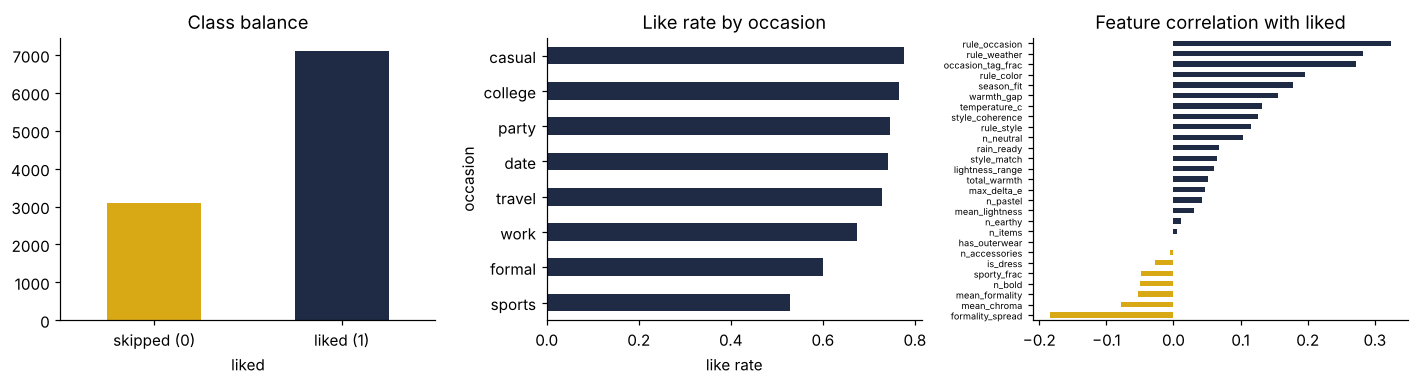

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
INK, ACCENT = "#1f2a44", "#d9a915"

df["liked"].value_counts().sort_index().plot.bar(ax=axes[0], color=[ACCENT, INK])
axes[0].set_xticklabels(["skipped (0)", "liked (1)"], rotation=0)
axes[0].set_title("Class balance")

df.groupby("occasion")["liked"].mean().sort_values().plot.barh(ax=axes[1], color=INK)
axes[1].set_title("Like rate by occasion"); axes[1].set_xlabel("like rate")

corr.plot.barh(ax=axes[2], color=[ACCENT if v < 0 else INK for v in corr])
axes[2].set_title("Feature correlation with liked"); axes[2].tick_params(axis="y", labelsize=6)
plt.tight_layout(); plt.show()

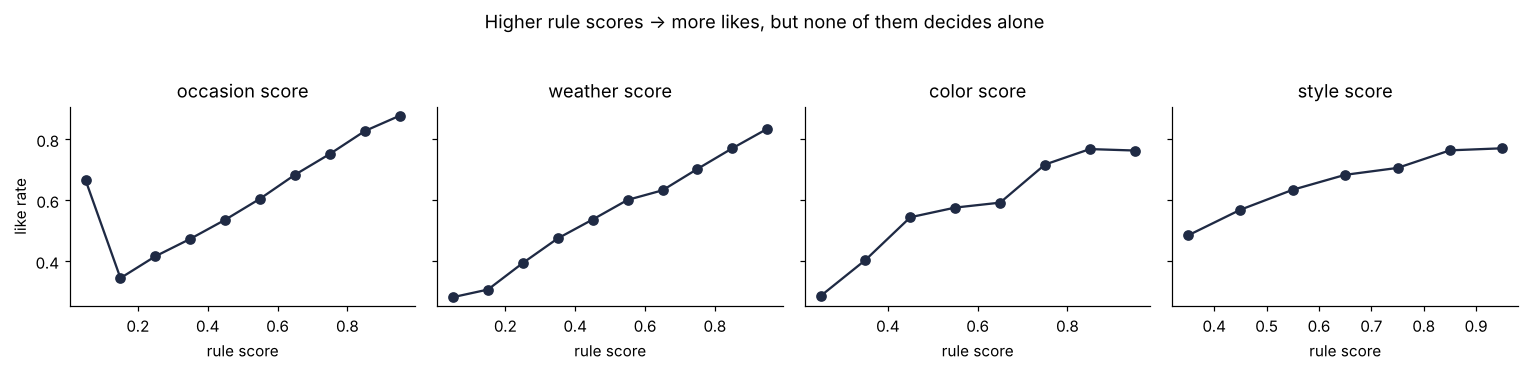

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for ax, col in zip(axes, ["rule_occasion", "rule_weather", "rule_color", "rule_style"]):
    bins = pd.cut(df[col], bins=np.linspace(0, 1, 11))
    rate = df.groupby(bins, observed=True)["liked"].mean()
    ax.plot([b.mid for b in rate.index], rate.values, marker="o", color=INK)
    ax.set_title(col.replace("rule_", "") + " score"); ax.set_xlabel("rule score")
axes[0].set_ylabel("like rate")
plt.suptitle("Higher rule scores → more likes, but none of them decides alone", y=1.04)
plt.tight_layout(); plt.show()

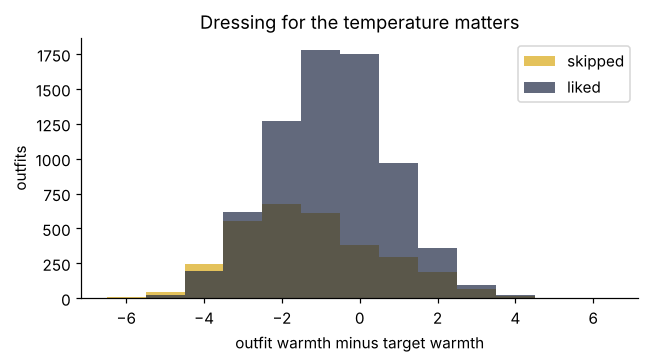

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for liked, colour in ((0, ACCENT), (1, INK)):
    ax.hist(df.loc[df.liked == liked, "warmth_gap"], bins=np.arange(-6.5, 7.5, 1), alpha=0.7,
            color=colour, label=["skipped", "liked"][liked])
ax.set_xlabel("outfit warmth minus target warmth"); ax.set_ylabel("outfits"); ax.legend()
ax.set_title("Dressing for the temperature matters")
plt.tight_layout(); plt.show()

## 8. Feature engineering

* Numeric features come straight from `features.build_features`.
* The four categorical fields are one-hot encoded with encoders fitted on the **fixed vocabularies**
  from `catalog.py` (not on the data), so an occasion that's rare in training still gets its column.
* Train/test split is **grouped by person**: nobody's ratings appear on both sides, so the test score
  measures how well the models handle someone new.
* KNN needs standardised features (distances); the Decision Tree doesn't, so it gets the raw matrix.

In [14]:
encoders = features.make_encoders()
X = features.to_matrix(df.to_dict("records"), encoders)
y = df["liked"].to_numpy()
groups = df["person_id"].to_numpy()
names = features.feature_names()
assert X.shape[1] == len(names)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test, y_train, y_test = X[train_idx], X[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]

scaler = StandardScaler().fit(X_train)
Xs_train, Xs_test = scaler.transform(X_train), scaler.transform(X_test)

print(f"Matrix: {X.shape[0]:,} rows × {X.shape[1]} columns")
print(f"Train: {len(train_idx):,} rows ({len(set(g_train))} people) | Test: {len(test_idx):,} rows "
      f"({len(set(groups[test_idx]))} people)")
print(f"Like rate train {y_train.mean():.3f} / test {y_test.mean():.3f}")

Matrix: 10,192 rows × 53 columns
Train: 8,151 rows (256 people) | Test: 2,041 rows (64 people)
Like rate train 0.704 / test 0.665


## 9. KNN training

KNN measures distance across every column, so 53 mostly-noise dimensions would drown out the few that
matter. The KNN model is therefore a small pipeline: keep the *k* most informative features
(ANOVA F-test, fitted on training data only), then vote among the nearest neighbours.

In [15]:
cv = GroupKFold(n_splits=5)
knn_search = GridSearchCV(
    Pipeline([("select", SelectKBest(f_classif)), ("knn", KNeighborsClassifier())]),
    {"select__k": [6, 10, 16, 24],
     "knn__n_neighbors": [25, 51, 81, 121],
     "knn__weights": ["uniform", "distance"]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
knn_search.fit(Xs_train, y_train, groups=g_train)
knn = knn_search.best_estimator_
print("Best KNN:", knn_search.best_params_, "| CV ROC AUC = {:.3f}".format(knn_search.best_score_))
kept = np.array(names)[knn.named_steps["select"].get_support()]
print("Features KNN keeps:", ", ".join(kept))

Best KNN: {'knn__n_neighbors': 121, 'knn__weights': 'uniform', 'select__k': 6} | CV ROC AUC = 0.779
Features KNN keeps: formality_spread, occasion_tag_frac, season_fit, rule_occasion, rule_weather, rule_color


## 10. Decision Tree training

In [16]:
dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=SEED),
    {"max_depth": [5, 7, 9, 12], "min_samples_leaf": [15, 30, 60, 100], "criterion": ["gini", "entropy"]},
    scoring="roc_auc", cv=cv, n_jobs=-1,
)
dt_search.fit(X_train, y_train, groups=g_train)
dt = dt_search.best_estimator_
print("Best Decision Tree:", dt_search.best_params_, "| CV ROC AUC = {:.3f}".format(dt_search.best_score_))
print("Depth:", dt.get_depth(), "| leaves:", dt.get_n_leaves())

Best Decision Tree: {'criterion': 'gini', 'max_depth': 7, 'min_samples_leaf': 100} | CV ROC AUC = 0.759
Depth: 7 | leaves: 45


## 11. Model evaluation (held-out people)

In [17]:
def evaluate(name, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_test, pred),
            "precision": precision_score(y_test, pred, zero_division=0),
            "recall": recall_score(y_test, pred, zero_division=0),
            "f1": f1_score(y_test, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_test, proba) if len(set(y_test)) > 1 else float("nan")}

p_dt = dt.predict_proba(X_test)[:, 1]
p_knn = knn.predict_proba(Xs_test)[:, 1]
results = [evaluate("Decision Tree", p_dt), evaluate("KNN", p_knn)]
pd.DataFrame(results).set_index("model").round(3)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Decision Tree,0.735,0.760,0.880,0.816,0.795
KNN,0.739,0.742,0.932,0.826,0.809


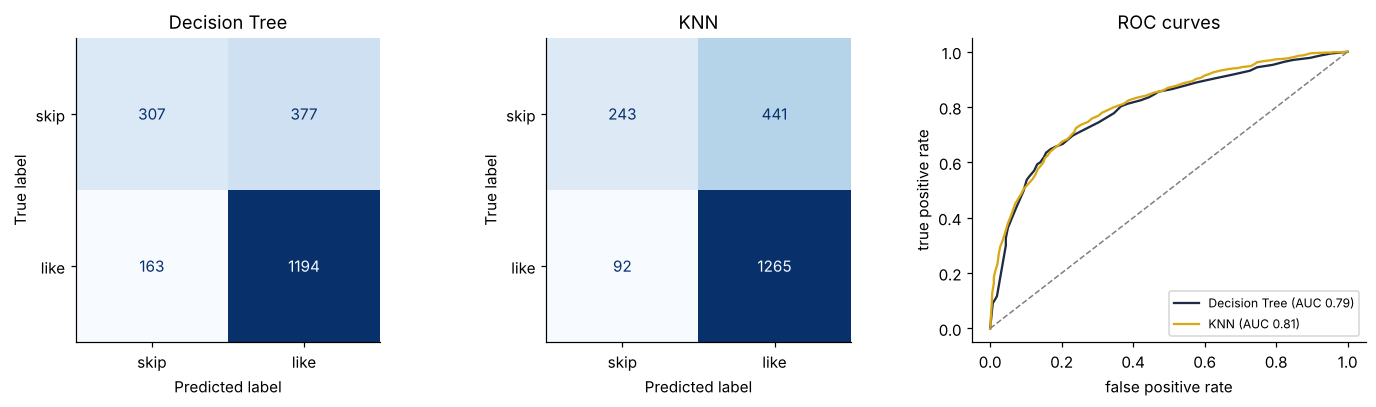

              precision    recall  f1-score   support

        skip       0.65      0.45      0.53       684
        like       0.76      0.88      0.82      1357

    accuracy                           0.74      2041
   macro avg       0.71      0.66      0.67      2041
weighted avg       0.72      0.74      0.72      2041



In [18]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, proba) in zip(axes[:2], (("Decision Tree", p_dt), ("KNN", p_knn))):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (proba >= 0.5).astype(int)),
                           display_labels=["skip", "like"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
for name, proba, colour in (("Decision Tree", p_dt, INK), ("KNN", p_knn, ACCENT)):
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[2].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, proba):.2f})", color=colour)
axes[2].plot([0, 1], [0, 1], ls="--", color="grey", lw=1)
axes[2].set_xlabel("false positive rate"); axes[2].set_ylabel("true positive rate"); axes[2].legend(fontsize=8)
axes[2].set_title("ROC curves")
plt.tight_layout(); plt.show()

print(classification_report(y_test, (p_dt >= 0.5).astype(int), target_names=["skip", "like"]))

Decision Tree — most important features:
rule_occasion       0.416
rule_weather        0.289
rule_color          0.164
formality_spread    0.048
rule_style          0.028
style_coherence     0.016
mean_lightness      0.009
palette=any         0.008
palette=bold        0.007
rain_ready          0.006
style_match         0.003
mean_chroma         0.003


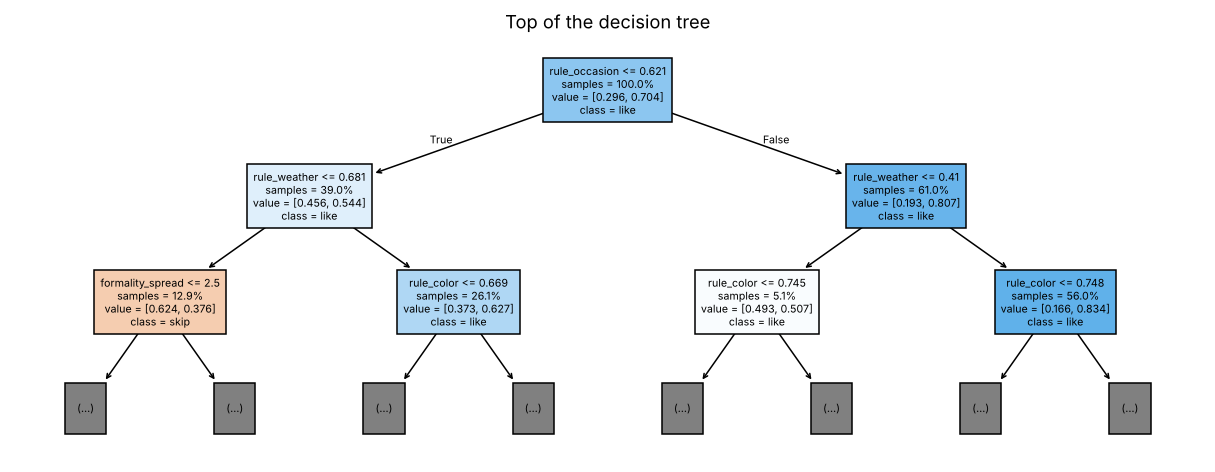

In [19]:
importance = pd.Series(dt.feature_importances_, index=names).sort_values(ascending=False)
print("Decision Tree — most important features:")
print(importance.head(12).round(3).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
plot_tree(dt, max_depth=2, feature_names=names, class_names=["skip", "like"], filled=True,
          impurity=False, proportion=True, fontsize=7, ax=ax)
ax.set_title("Top of the decision tree"); plt.show()

## 12. Colour compatibility analysis

The colour rules use **CIEDE2000** distances in CIELAB space. First, the implementation is checked
against published test pairs (Sharma, Wu & Dalal, 2005). Then the named swatches are compared with
each other, and the data shows how the weakest colour pair in an outfit relates to whether it was liked.

In [20]:
sharma = [  # (Lab1, Lab2, expected ΔE00)
    ((50, 2.6772, -79.7751), (50, 0, -82.7485), 2.0425),
    ((50, -1.3802, -84.2814), (50, 0, -82.7485), 1.0000),
    ((50, 0, 0), (50, -1, 2), 2.3669),
    ((50, 2.49, -0.001), (50, -2.49, 0.0009), 7.1792),
    ((60.2574, -34.0099, 36.2677), (60.4626, -34.1751, 39.4387), 1.2644),
    ((22.7233, 20.0904, -46.694), (23.0331, 14.973, -42.5619), 2.0373),
    ((90.8027, -2.0831, 1.441), (91.1528, -1.6435, 0.0447), 1.4441),
    ((2.0776, 0.0795, -1.135), (0.9033, -0.0636, -0.5514), 0.9082),
]
errors = [abs(color.delta_e_2000(a, b) - e) for a, b, e in sharma]
print(f"Max error vs reference values: {max(errors):.5f}")
assert max(errors) < 1e-3

Max error vs reference values: 0.00004


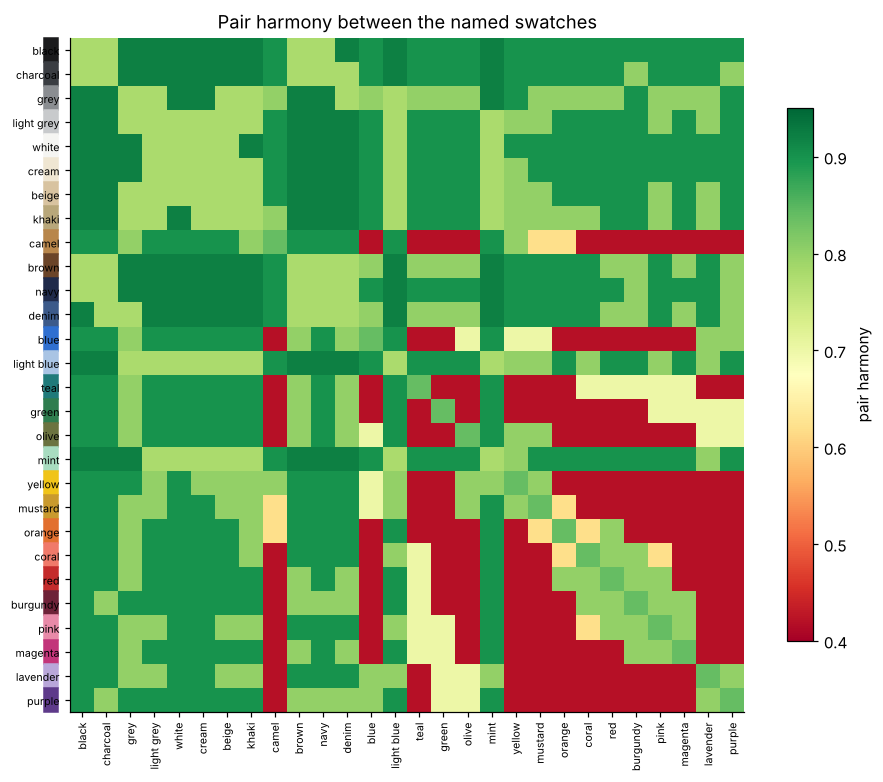

In [21]:
swatches = list(color.NAMED_COLORS)
H = np.array([[color.pair_harmony(color.NAMED_COLORS[a], color.NAMED_COLORS[b])[0] for b in swatches] for a in swatches])
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(H, cmap="RdYlGn", vmin=0.4, vmax=0.95)
ax.set_xticks(range(len(swatches)), swatches, rotation=90, fontsize=7)
ax.set_yticks(range(len(swatches)), swatches, fontsize=7)
for i, name in enumerate(swatches):
    ax.add_patch(plt.Rectangle((-1.6, i - 0.5), 0.6, 1, color=color.NAMED_COLORS[name], clip_on=False))
fig.colorbar(im, ax=ax, shrink=0.7, label="pair harmony")
ax.set_title("Pair harmony between the named swatches")
plt.tight_layout(); plt.show()

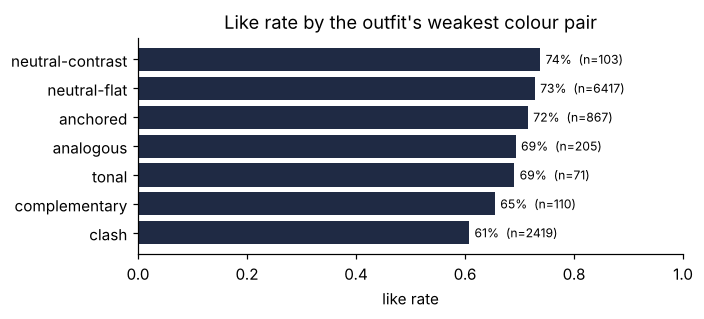

In [22]:
kinds = df.groupby("harmony_kind")["liked"].agg(["mean", "count"]).sort_values("mean")
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.barh(kinds.index, kinds["mean"], color=INK)
for i, (m, n) in enumerate(zip(kinds["mean"], kinds["count"])):
    ax.text(m + 0.01, i, f"{m:.0%}  (n={n})", va="center", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("like rate")
ax.set_title("Like rate by the outfit's weakest colour pair")
plt.tight_layout(); plt.show()

## 13. Model comparison

Baselines show what the models add:

* **Majority class** — always predicts the most common answer.
* **Rules only** — the average of the four rule scores, used directly as a probability.
* **ML blend** — the weighted average of Decision Tree and KNN. Weights come from each model's
  cross-validated AUC above chance.
* **Hybrid (deployed)** — what the app actually ranks by: the four rule scores and the ML blend,
  combined with the weights in `services/recommender.py`.

In [23]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
p_dummy = dummy.predict_proba(X_test)[:, 1]
test_df = df.iloc[test_idx]
p_rules = test_df[["rule_occasion", "rule_weather", "rule_color", "rule_style"]].mean(axis=1).to_numpy()

edge_dt = max(dt_search.best_score_ - 0.5, 0.01)
edge_knn = max(knn_search.best_score_ - 0.5, 0.01)
blend = {"decision_tree": round(float(edge_dt / (edge_dt + edge_knn)), 3),
         "knn": round(float(edge_knn / (edge_dt + edge_knn)), 3)}
p_blend = blend["decision_tree"] * p_dt + blend["knn"] * p_knn

from fitcheck_ml.recommender import WEIGHTS
w = {k: WEIGHTS[k] for k in ("occasion", "weather", "color", "style", "ml")}
p_hybrid = (w["occasion"] * test_df["rule_occasion"] + w["weather"] * test_df["rule_weather"]
            + w["color"] * test_df["rule_color"] + w["style"] * test_df["rule_style"]
            + w["ml"] * p_blend).to_numpy() / sum(w.values())

comparison = pd.DataFrame([
    evaluate("Majority class", p_dummy),
    evaluate("Rules only", p_rules, threshold=np.median(p_rules)),
    evaluate("KNN", p_knn),
    evaluate("Decision Tree", p_dt),
    evaluate("ML blend", p_blend),
    evaluate("Hybrid (deployed)", p_hybrid, threshold=np.median(p_hybrid)),
]).set_index("model").round(3)
print("Blend weights:", blend)
comparison

Blend weights: {'decision_tree': 0.481, 'knn': 0.519}


,accuracy,precision,recall,f1,roc_auc
model,,,,,
Majority class,0.665,0.665,1.000,0.799,0.500
Rules only,0.712,0.877,0.660,0.753,0.811
KNN,0.739,0.742,0.932,0.826,0.809
Decision Tree,0.735,0.760,0.880,0.816,0.795
ML blend,0.733,0.745,0.912,0.820,0.811
Hybrid (deployed),0.721,0.885,0.666,0.760,0.818


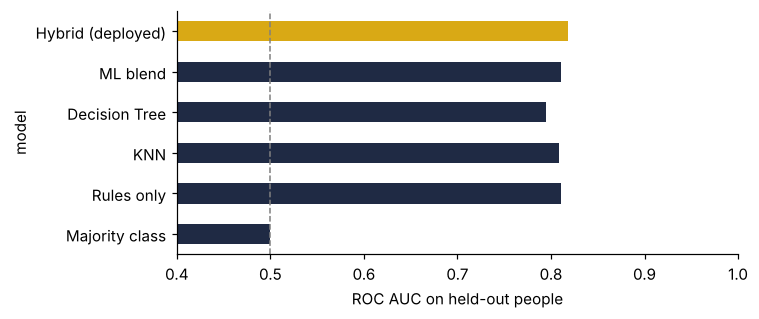

In [24]:
fig, ax = plt.subplots(figsize=(7, 3))
comparison["roc_auc"].plot.barh(ax=ax, color=[ACCENT if "Hybrid" in i else INK for i in comparison.index])
ax.axvline(0.5, ls="--", color="grey", lw=1)
ax.set_xlim(0.4, 1); ax.set_xlabel("ROC AUC on held-out people")
plt.tight_layout(); plt.show()

## 14. Model export

In [25]:
joblib.dump(dt, EXPORT_DIR / "decision_tree_model.joblib")
joblib.dump(knn, EXPORT_DIR / "knn_model.joblib")
joblib.dump(scaler, EXPORT_DIR / "scaler.joblib")
joblib.dump(encoders, EXPORT_DIR / "encoders.joblib")

metadata = {
    "model_version": "1.0.0",
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "author": "Swayam Shakya",
    "dataset": {"source": "synthetic (see notebook section 2)", "rows": int(len(df)),
                "people": int(df["person_id"].nunique()), "like_rate": round(float(y.mean()), 4)},
    "feature_names": names,
    "numeric_features": features.NUMERIC_FEATURES,
    "categorical_features": features.CATEGORICAL_FEATURES,
    "decision_tree": {"params": dt_search.best_params_, "cv_roc_auc": round(dt_search.best_score_, 4)},
    "knn": {"params": knn_search.best_params_, "cv_roc_auc": round(knn_search.best_score_, 4)},
    "blend": blend,
    "test_metrics": {k: {m: round(float(v), 4) for m, v in row.items()}
                     for k, row in comparison.to_dict("index").items()},
    "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(EXPORT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2))
for f in sorted(EXPORT_DIR.glob("*")):
    if f.is_file() and not f.name.startswith("."):
        print(f"{f.name:32s} {f.stat().st_size / 1024:8.1f} KB")

decision_tree_model.joblib            8.2 KB
encoders.joblib                       2.0 KB
knn_model.joblib                    958.0 KB
model_metadata.json                   3.8 KB
scaler.joblib                         1.8 KB


In [26]:
# Load the Joblib files back and check the predictions match.
ml.reset_bundle()
bundle = ml.ModelBundle(EXPORT_DIR).load()
print("Bundle available:", bundle.available, "|", bundle.reason)
assert bundle.available

sample = df.iloc[test_idx[:200]].to_dict("records")
blended, dt_p, knn_p = bundle.predict(sample)
assert np.allclose(dt_p, p_dt[:200]) and np.allclose(knn_p, p_knn[:200])
print("Reloaded models reproduce the notebook's predictions on 200 test outfits.")

Bundle available: True | ok


Reloaded models reproduce the notebook's predictions on 200 test outfits.


## 15. Conclusion

* Both models clearly beat the majority-class baseline on people they never saw in training.
  Exact figures are in the comparison table above and in `model_metadata.json`.
* The rule scores on their own are a strong baseline, which is expected: the simulated taste mostly
  rewards dressing for the occasion and the weather, and the rules encode exactly that. On their own
  the ML models land close to the rules rather than far above them. Combined in the **hybrid**
  score the app uses, they edge ahead of rules alone; on this simulated data the gain is small.
  Where the models matter more is taste the rules don't encode (palette preferences interacting
  with bold colours), and that grows with real feedback.
* The Decision Tree is the more interpretable of the two (its top splits are shown above);
  KNN is smoother. The app blends them with weights set from cross-validated AUC.
* Personal taste on top of this comes from each person's own likes and dislikes at runtime
  (a nearest-neighbour lookup over their rated outfits in `ml/fitcheck_ml/ml.py`).

**Limitations.** The training data is simulated, so these metrics show the pipeline works, not
how well it predicts real people. Retraining on exported real feedback is the next step.

— Swayam Shakya